<a href="https://colab.research.google.com/github/Andru-1987/data_science_ii_96085/blob/main/12_semana/reduccion_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd


In [ ]:
RNG = 42

def generar_clientes(seed=RNG):
    rng = np.random.default_rng(seed)
    cols = ["edad", "ingreso_anual", "gasto_promedio",
            "frecuencia_compras", "visitas_web_mes", "pct_descuento"]

    # (n, medias, desvíos) por perfil
    perfiles = {
        "Cazadores de ofertas": (240, [27, 38000, 60, 20, 30, 0.80],
                                      [4, 6000, 12, 4, 6, 0.07]),
        "Compradores premium":  (160, [45, 110000, 260, 8, 12, 0.10],
                                      [6, 15000, 40, 2, 3, 0.05]),
        "Ocasionales":          (200, [38, 65000, 110, 3, 5, 0.35],
                                      [8, 10000, 25, 1, 2, 0.10]),
    }

    partes = []

    for nombre, (n, mu, sd) in perfiles.items():
        df_p = pd.DataFrame(rng.normal(mu, sd, size=(n, len(cols))), columns=cols)
        df_p["perfil"] = nombre
        partes.append(df_p)

    # Clientes atípicos (valores extremos)
    n_out = 12
    atipicos = pd.DataFrame({
        "edad": rng.uniform(25, 60, n_out),
        "ingreso_anual": rng.uniform(200_000, 300_000, n_out),
        "gasto_promedio": rng.uniform(600, 900, n_out),
        "frecuencia_compras": rng.uniform(25, 40, n_out),
        "visitas_web_mes": rng.uniform(45, 70, n_out),
        "pct_descuento": rng.uniform(0, 1, n_out),
    })
    atipicos["perfil"] = "Atipico"
    partes.append(atipicos)

    df = pd.concat(partes, ignore_index=True)

    # Variables redundantes (correlacionadas con otras) -> útiles para PCA
    df["tiempo_sesion_min"] = 0.8 * df["visitas_web_mes"] + rng.normal(0, 2, len(df))
    df["gasto_anual"] = df["gasto_promedio"] * df["frecuencia_compras"] + rng.normal(0, 100, len(df))

    df["pct_descuento"] = df["pct_descuento"].clip(0, 1)
    num = df.select_dtypes("number").columns
    df[num] = df[num].clip(lower=0)

    # Tipos finales: enteros y 3 decimales
    cols_int = ["edad", "frecuencia_compras", "visitas_web_mes"]
    cols_float = [c for c in num if c not in cols_int]

    df[cols_int] = df[cols_int].round().astype(int)
    df[cols_float] = df[cols_float].round(3)
    return df


df = generar_clientes()
FEATURES = [c for c in df.columns if c != "perfil"]

In [ ]:
df.head()

,edad,ingreso_anual,gasto_promedio,frecuencia_compras,visitas_web_mes,pct_descuento,perfil,tiempo_sesion_min,gasto_anual
0,28,31760.095,69.005,24,18,0.709,Cazadores de ofertas,15.611,1719.510
1,28,36102.544,59.798,17,35,0.854,Cazadores de ofertas,29.275,945.551
2,27,44763.447,65.610,17,32,0.733,Cazadores de ofertas,26.904,1045.655
3,31,37700.445,57.782,17,37,0.789,Cazadores de ofertas,26.003,1167.484
4,25,35887.199,66.388,21,32,0.830,Cazadores de ofertas,23.259,1353.385


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   edad                612 non-null    int64  
 1   ingreso_anual       612 non-null    float64
 2   gasto_promedio      612 non-null    float64
 3   frecuencia_compras  612 non-null    int64  
 4   visitas_web_mes     612 non-null    int64  
 5   pct_descuento       612 non-null    float64
 6   perfil              612 non-null    object 
 7   tiempo_sesion_min   612 non-null    float64
 8   gasto_anual         612 non-null    float64
dtypes: float64(5), int64(3), object(1)
memory usage: 43.2+ KB


In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score
from sklearn.datasets import make_moons, make_blobs

## Colores de agrupaciones

In [ ]:
COLORES = {"Cazadores de ofertas": "tab:blue", "Compradores premium": "tab:orange", "Ocasionales": "tab:green", "Atipico": "tab:red"}


In [ ]:
df.perfil.value_counts(normalize=True)

,proportion
perfil,
Cazadores de ofertas,0.392157
Ocasionales,0.326797
Compradores premium,0.261438
Atipico,0.019608


## PCA

In [ ]:
X = df[FEATURES].values
X

array([[2.80000000e+01, 3.17600950e+04, 6.90050000e+01, ...,
        7.09000000e-01, 1.56110000e+01, 1.71951000e+03],
       [2.80000000e+01, 3.61025440e+04, 5.97980000e+01, ...,
        8.54000000e-01, 2.92750000e+01, 9.45551000e+02],
       [2.70000000e+01, 4.47634470e+04, 6.56100000e+01, ...,
        7.33000000e-01, 2.69040000e+01, 1.04565500e+03],
       ...,
       [5.10000000e+01, 2.33127679e+05, 8.80405000e+02, ...,
        4.65000000e-01, 5.12130000e+01, 3.42279640e+04],
       [4.00000000e+01, 2.67009317e+05, 7.42562000e+02, ...,
        3.44000000e-01, 4.90320000e+01, 2.85553140e+04],
       [3.50000000e+01, 2.43903511e+05, 7.91486000e+02, ...,
        2.62000000e-01, 3.27240000e+01, 2.65128590e+04]])

PC1 sin estandarizar: 99.4% de la varianza (domina la variable de mayor escala)
PC1 estandarizado:    52.1%
Componentes para retener 90% de varianza: 3 de 8


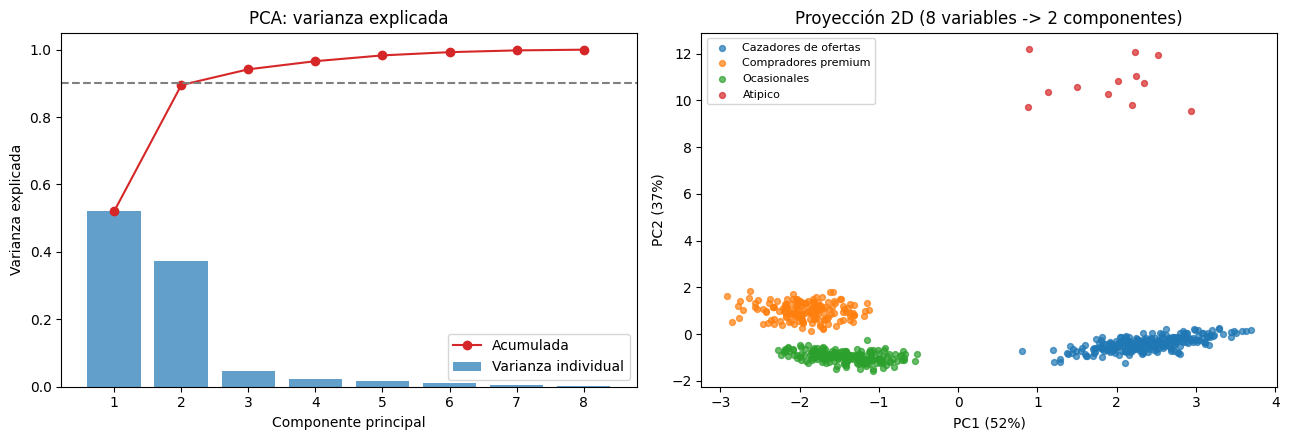

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_full = PCA().fit(X_scaled)
var = pca_full.explained_variance_ratio_
cum = np.cumsum(var)
n_comp_90 = int(np.argmax(cum >= 0.90) + 1)

# Demostración de la "regla de oro": PCA sin estandarizar
var_sin_escalar = PCA().fit(X).explained_variance_ratio_[0]
print(f"PC1 sin estandarizar: {var_sin_escalar:.1%} de la varianza (domina la variable de mayor escala)")
print(f"PC1 estandarizado:    {var[0]:.1%}")
print(f"Componentes para retener 90% de varianza: {n_comp_90} de {len(FEATURES)}")

X_2d = pca_full.transform(X_scaled)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Scree plot + varianza acumulada
axes[0].bar(range(1, len(var) + 1), var, alpha=0.7, label="Varianza individual")
axes[0].plot(range(1, len(var) + 1), cum, "o-", color="tab:red", label="Acumulada")
axes[0].axhline(0.90, ls="--", color="gray")
axes[0].set(xlabel="Componente principal", ylabel="Varianza explicada",
            title="PCA: varianza explicada")
axes[0].legend()

# (b) Proyección 2D coloreada por perfil real
for perfil, color in COLORES.items():
    m = df["perfil"] == perfil
    axes[1].scatter(X_2d[m, 0], X_2d[m, 1], s=18, alpha=0.7, c=color, label=perfil)
axes[1].set(xlabel=f"PC1 ({var[0]:.0%})", ylabel=f"PC2 ({var[1]:.0%})",
            title="Proyección 2D (8 variables -> 2 componentes)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


                              Sin estandarizar   Estandarizado
PC1                                      99.4%           52.1%
PC2                                       0.6%           37.4%
Componentes para 90%                         1               3

Variable dominante en PC1 sin estandarizar: ingreso_anual (0.998)
Variable dominante en PC1 estandarizado:    pct_descuento (0.448)


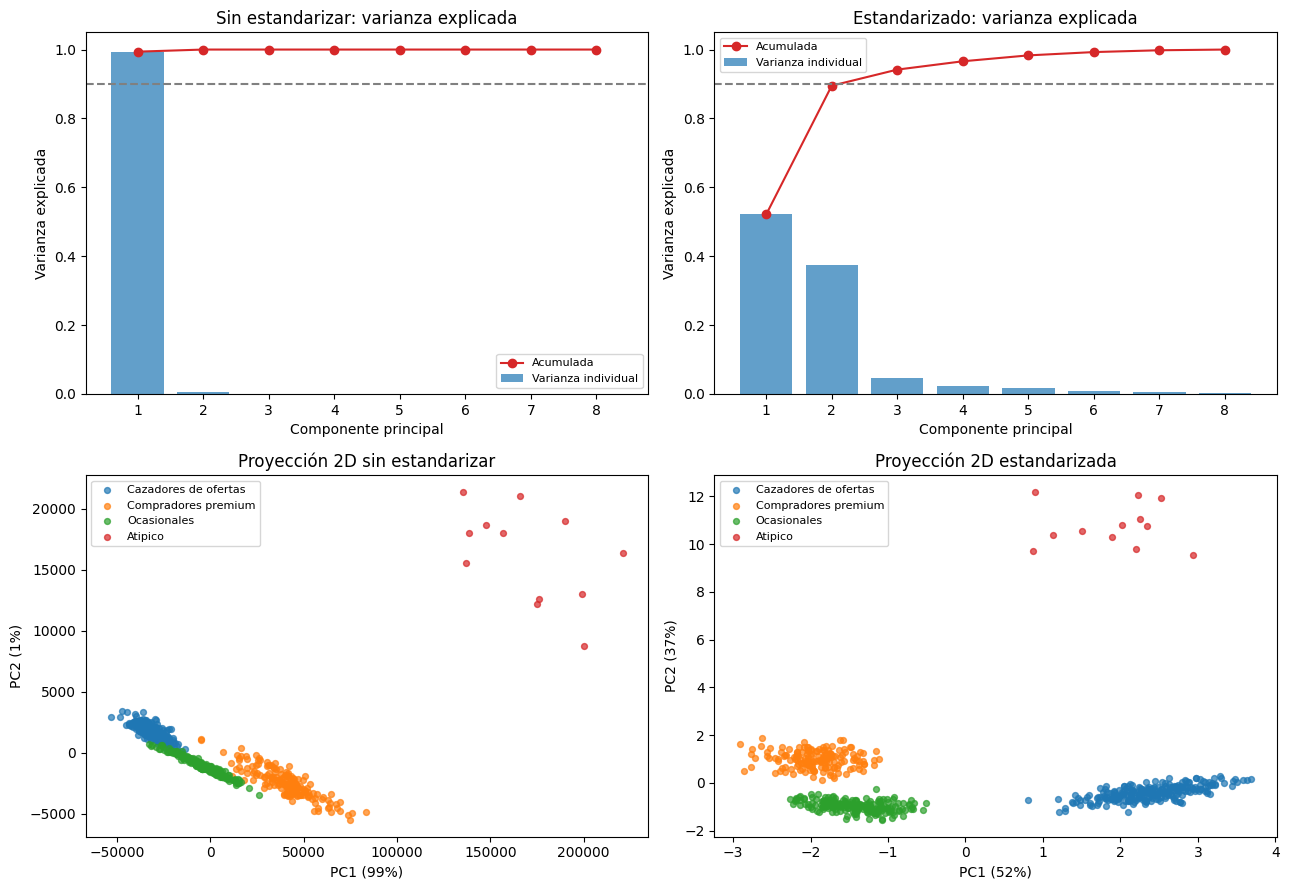

In [ ]:
pca_esc = PCA().fit(X_scaled)
pca_raw = PCA().fit(X)

var_esc, var_raw = pca_esc.explained_variance_ratio_, pca_raw.explained_variance_ratio_
cum_esc, cum_raw = np.cumsum(var_esc), np.cumsum(var_raw)

n90_esc = int(np.argmax(cum_esc >= 0.90) + 1)
n90_raw = int(np.argmax(cum_raw >= 0.90) + 1)

print(f"{'':28s}{'Sin estandarizar':>18s}{'Estandarizado':>16s}")
print(f"{'PC1':28s}{var_raw[0]:>18.1%}{var_esc[0]:>16.1%}")
print(f"{'PC2':28s}{var_raw[1]:>18.1%}{var_esc[1]:>16.1%}")
print(f"{'Componentes para 90%':28s}{n90_raw:>18d}{n90_esc:>16d}")

# --- Qué variable domina PC1 en cada caso (|carga| máxima) ---
carga_raw = pd.Series(np.abs(pca_raw.components_[0]), index=FEATURES).sort_values(ascending=False)
carga_esc = pd.Series(np.abs(pca_esc.components_[0]), index=FEATURES).sort_values(ascending=False)
print(f"\nVariable dominante en PC1 sin estandarizar: {carga_raw.index[0]} ({carga_raw.iloc[0]:.3f})")
print(f"Variable dominante en PC1 estandarizado:    {carga_esc.index[0]} ({carga_esc.iloc[0]:.3f})")

# --- Proyecciones 2D ---
X_2d_esc = pca_esc.transform(X_scaled)[:, :2]
X_2d_raw = pca_raw.transform(X)[:, :2]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Fila 1: scree + acumulada
for ax, v, c, titulo in [
    (axes[0, 0], var_raw, cum_raw, "Sin estandarizar: varianza explicada"),
    (axes[0, 1], var_esc, cum_esc, "Estandarizado: varianza explicada"),
]:
    ax.bar(range(1, len(v) + 1), v, alpha=0.7, label="Varianza individual")
    ax.plot(range(1, len(v) + 1), c, "o-", color="tab:red", label="Acumulada")
    ax.axhline(0.90, ls="--", color="gray")
    ax.set(xlabel="Componente principal", ylabel="Varianza explicada",
           title=titulo, ylim=(0, 1.05))
    ax.legend(fontsize=8)

# Fila 2: proyección 2D coloreada por perfil
for ax, X2, v, titulo in [
    (axes[1, 0], X_2d_raw, var_raw, "Proyección 2D sin estandarizar"),
    (axes[1, 1], X_2d_esc, var_esc, "Proyección 2D estandarizada"),
]:
    for perfil, color in COLORES.items():
        m = (df["perfil"] == perfil).values
        ax.scatter(X2[m, 0], X2[m, 1], s=18, alpha=0.7, c=color, label=perfil)
    ax.set(xlabel=f"PC1 ({v[0]:.0%})", ylabel=f"PC2 ({v[1]:.0%})", title=titulo)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Agurpacion implementando K-Means

In [ ]:
pca90 = PCA(n_components=n_comp_90).fit(X_scaled)
X_pca = pca90.transform(X_scaled)

In [ ]:
X_pca

array([[ 1.70304133, -0.62336673, -0.1758172 ],
       [ 2.67620097, -0.31657985,  0.42417669],
       [ 2.27432697, -0.24799058,  0.15178322],
       ...,
       [ 2.22878117, 12.05342038,  0.32211802],
       [ 2.01393906, 10.81807027, -0.53519518],
       [ 0.87705886,  9.70628935, -1.55479769]])

In [ ]:
ks = range(2,9)
inercias, sils = [],[]

for k  in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RNG).fit(X_pca)
    inercias.append(km.inertia_)
    sils.append(silhouette_score(X_pca,km.labels_))



In [ ]:
k_opt = list(ks)[int(np.argmax(sils))]
km = KMeans(n_clusters=k_opt, n_init =10, random_state=RNG).fit(X_pca)
print(f"Valor optimo de K elegido por el metodo de siluhete es -> {k_opt}")

Valor optimo de K elegido por el metodo de siluhete es -> 3


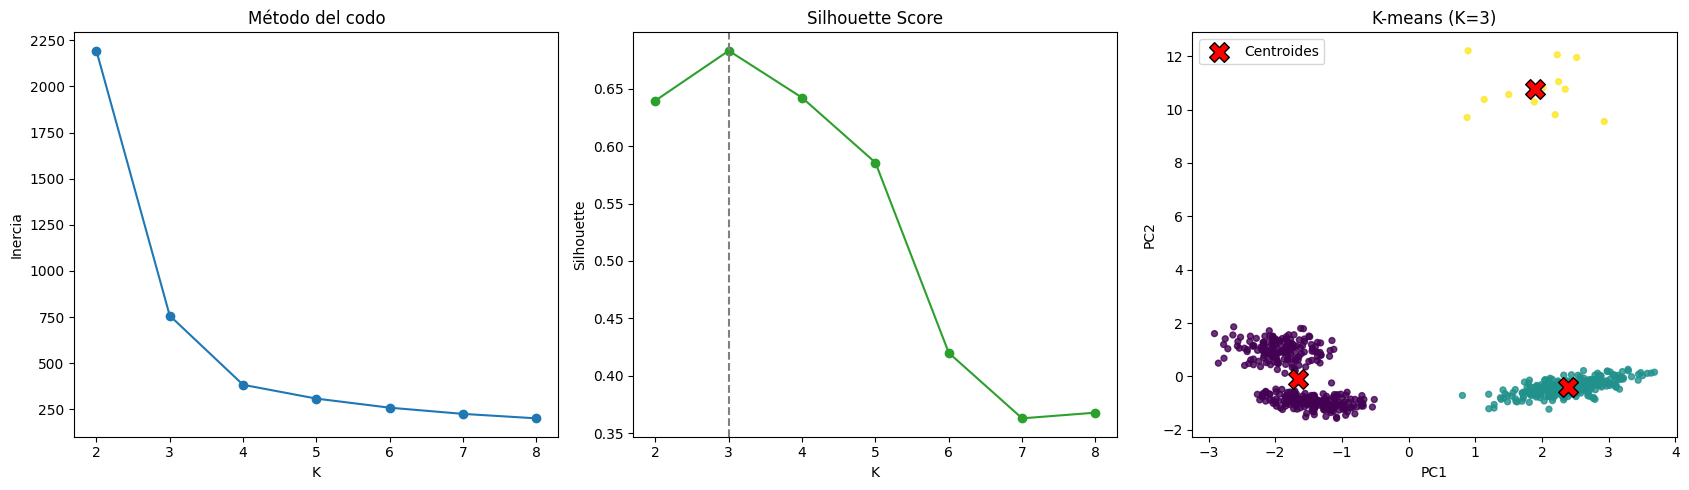

In [ ]:
fig, axes = plt.subplots(1,3, figsize=(17,5))

axes[0].plot(list(ks), inercias, "o-")
axes[0].set(xlabel="K", ylabel="Inercia", title="Método del codo")

axes[1].plot(list(ks), sils, "o-", color="tab:green")
axes[1].axvline(k_opt, ls="--", color="gray")
axes[1].set(xlabel="K", ylabel="Silhouette", title="Silhouette Score")

sc = axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=km.labels_, cmap="viridis", s=18, alpha=0.8)
axes[2].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
                c="red", marker="X", s=200, edgecolor="black", label="Centroides")
axes[2].set(xlabel="PC1", ylabel="PC2", title=f"K-means (K={k_opt})")
axes[2].legend()
plt.tight_layout()
plt.show()



In [ ]:
DBSCAN(eps=0.15, min_samples=8).fit_predict(X_pca)

array([-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  0, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  0, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1,  0, -1, -1, -1, -1, -1, -1, -1,  0, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1,  0, -1, -1, -1,  0, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  0, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1

In [ ]:
from sklearn.neighbors import NearestNeighbors

Clusters: 31 | Ruido: 502 (82.0%)


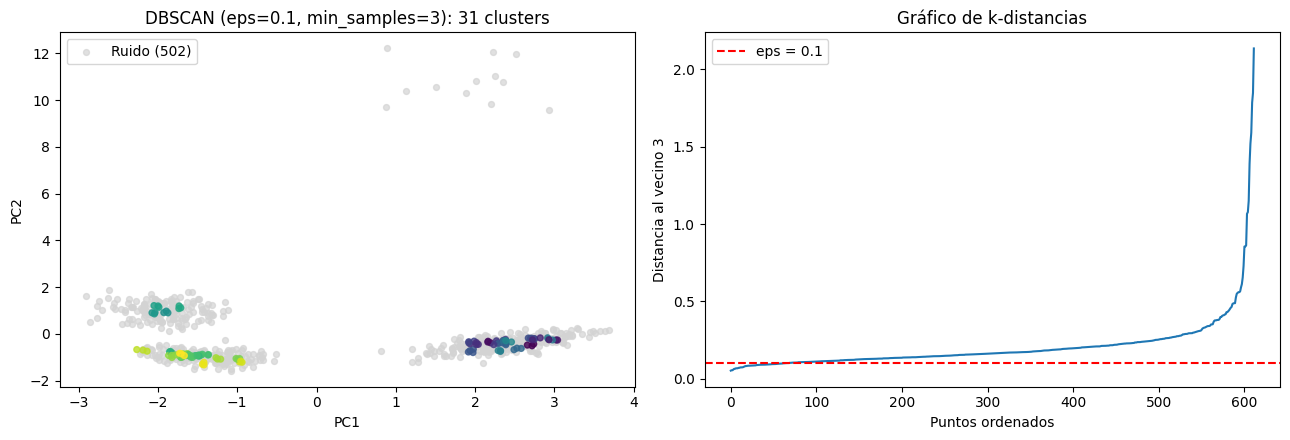

In [ ]:
EPS, MIN_S = 0.1, 3
labels_db = DBSCAN(eps=EPS, min_samples=MIN_S).fit_predict(X_pca)

n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_ruido = int((labels_db == -1).sum())
print(f"Clusters: {n_clusters} | Ruido: {n_ruido} ({n_ruido / len(labels_db):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Resultado de DBSCAN en el plano PC1-PC2
ruido = labels_db == -1
axes[0].scatter(X_pca[ruido, 0], X_pca[ruido, 1], c="lightgray", s=18,
                alpha=0.7, label=f"Ruido ({n_ruido})")
sc = axes[0].scatter(X_pca[~ruido, 0], X_pca[~ruido, 1], c=labels_db[~ruido],
                     cmap="viridis", s=18, alpha=0.8)
axes[0].set(xlabel="PC1", ylabel="PC2",
            title=f"DBSCAN (eps={EPS}, min_samples={MIN_S}): {n_clusters} clusters")
axes[0].legend()

# (b) Gráfico de k-distancias (k = min_samples) para elegir eps
dist, _ = NearestNeighbors(n_neighbors=MIN_S).fit(X_pca).kneighbors(X_pca)
k_dist = np.sort(dist[:, -1])
axes[1].plot(k_dist)
axes[1].axhline(EPS, ls="--", color="red", label=f"eps = {EPS}")
axes[1].set(xlabel="Puntos ordenados", ylabel=f"Distancia al vecino {MIN_S}",
            title="Gráfico de k-distancias")
axes[1].legend()

plt.tight_layout()
plt.show()

## DBSCAN vs Kmeans

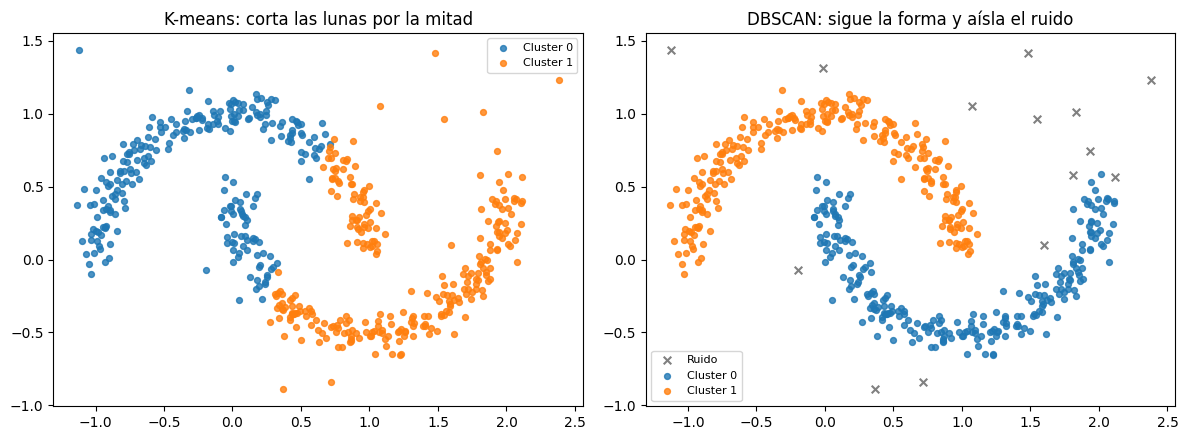

In [ ]:
rng = np.random.default_rng(RNG)
X_moons, _ = make_moons(n_samples=500, noise=0.07, random_state=RNG)
ruido = rng.uniform([-1.5, -1.0], [2.5, 1.5], size=(25, 2))
X_m = np.vstack([X_moons, ruido])

lab_km = KMeans(n_clusters=2, n_init=10, random_state=RNG).fit_predict(X_m)
lab_db = DBSCAN(eps=0.15, min_samples=8).fit_predict(X_m)


def plot_clusters(ax, X, labels, titulo):
    for lab in np.unique(labels):
        m = labels == lab
        if lab == -1:
            ax.scatter(X[m, 0], X[m, 1], c="gray", marker="x", s=30, label="Ruido")
        else:
            ax.scatter(X[m, 0], X[m, 1], s=18, alpha=0.8, label=f"Cluster {lab}")
    ax.set_title(titulo)
    ax.legend(fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_clusters(axes[0], X_m, lab_km, "K-means: corta las lunas por la mitad")
plot_clusters(axes[1], X_m, lab_db, "DBSCAN: sigue la forma y aísla el ruido")
plt.tight_layout()
plt.show()
